# Diagnóstico del ETL — MercadoLibre autos usados

Capa de presentación sobre la salida del pipeline. **Lee `data/processed/*.csv`; no
reimplementa nada del ETL.** Cada gráfico está para justificar una decisión de diseño o para
mostrar el efecto de una corrección de la auditoría.

Se commitea con las salidas renderizadas, así se ve en GitHub sin necesidad de los CSVs crudos
(~100 MB, fuera del repo).

Referencias: [README](../README.md) · [diccionario de datos](../docs/DATA_DICTIONARY.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# El notebook se puede abrir desde la raiz o desde notebooks/.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "etl").is_dir())
DATA = RAIZ / "data" / "processed"

fp = pd.read_csv(DATA / "fact_publicaciones.csv")
fph = pd.read_csv(DATA / "fact_precios_historicos.csv")
tt = pd.read_csv(DATA / "tabla_tendencias.csv")
dim_fx = pd.read_csv(DATA / "dim_FX.csv")

print("fact_publicaciones      {:>8,} filas x {} columnas".format(*fp.shape))
print("fact_precios_historicos {:>8,} filas x {} columnas".format(*fph.shape))
print("tabla_tendencias        {:>8,} filas x {} columnas".format(*tt.shape))

fact_publicaciones         6,586 filas x 37 columnas
fact_precios_historicos  124,511 filas x 9 columnas
tabla_tendencias           6,586 filas x 8 columnas


In [2]:
# Paleta: la instancia de referencia de la guia de visualizacion, modo claro,
# sin modificar. Los colores se asignan por el trabajo que hacen, no por gusto:
# azul = serie principal, rojo = marcado/critico, gris = neutro o sin dato.
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
S1, S2 = "#2a78d6", "#eb6834"          # categoricas 1 y 2
ROJO, CRITICO, NEUTRO = "#e34948", "#d03b3b", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "figure.dpi": 110,
})

MILES = FuncFormatter(lambda v, _: "{:,.0f}".format(v).replace(",", "."))

# Umbrales de la corrida sobre el dataset completo (salen del log del ETL).
TECHO_C1 = 1_144_000   # capa 1: Q3_global + 5*IQR_global
FENCE_C2 = 589_961     # capa 2: fence global

## 1. El dataset no tiene 124.511 publicaciones

Es el hecho del que se desprende todo el diseño. Las filas del CSV crudo son **capturas**: el
scraper volvió sobre los mismos avisos durante 73 días.

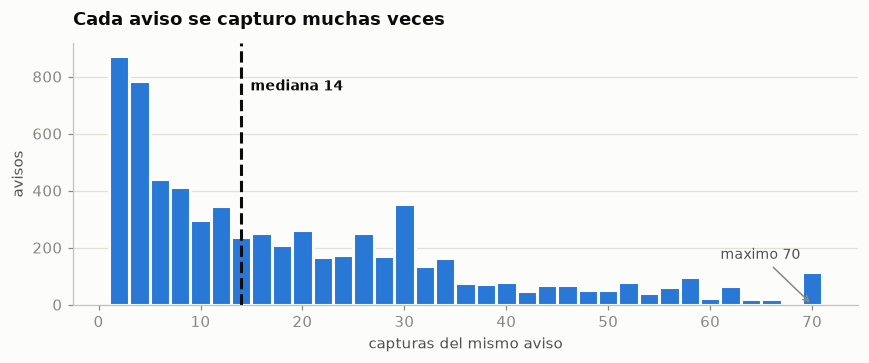

124,511 capturas  ->  6,586 avisos distintos
promedio 18.9 capturas por aviso


In [3]:
capturas = fph.groupby("id_publicacion").size()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(capturas, bins=range(1, 73, 2), color=S1, edgecolor=SURFACE, linewidth=2)
ax.axvline(capturas.median(), color=INK, linewidth=2, linestyle="--")
ax.annotate("mediana {:.0f}".format(capturas.median()),
            xy=(capturas.median(), ax.get_ylim()[1] * 0.82), xytext=(6, 0),
            textcoords="offset points", color=INK, fontsize=9, fontweight="bold")
ax.annotate("maximo {}".format(capturas.max()), xy=(capturas.max(), 0),
            xytext=(-60, 30), textcoords="offset points", color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=MUTED, linewidth=1))
ax.set_title("Cada aviso se capturo muchas veces")
ax.set_xlabel("capturas del mismo aviso")
ax.set_ylabel("avisos")
ax.yaxis.set_major_formatter(MILES)
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("{:,} capturas  ->  {:,} avisos distintos".format(len(fph), capturas.shape[0]))
print("promedio {:.1f} capturas por aviso".format(capturas.mean()))

**Qué dice:** tratar una captura como una publicación infla cualquier conteo unas 19 veces. De
acá sale todo lo demás: la deduplicación necesita un criterio determinístico, el gate de muestra
mínima de la capa 2 cuenta **avisos distintos** y no filas, y los cuartiles del IQR también.

In [4]:
# Avisos con mas de una captura el mismo dia: son los que obligan a un
# desempate determinístico dentro de la fecha.
intra_dia = fph.groupby(["id_publicacion", "fecha_captura"]).size()
intra_dia = intra_dia[intra_dia > 1]

print("pares (aviso, fecha) con mas de una captura:", len(intra_dia))
detalle = fph[fph["id_publicacion"].isin(intra_dia.index.get_level_values(0))]
detalle = detalle.sort_values(["id_publicacion", "fecha_captura", "__KEY_results"])
detalle.loc[detalle.duplicated(["id_publicacion", "fecha_captura"], keep=False),
            ["id_publicacion", "fecha_captura", "__KEY_results", "price_ars"]].head(10)

pares (aviso, fecha) con mas de una captura: 10


,id_publicacion,fecha_captura,__KEY_results,price_ars
24199,MLA580575432,2015-10-20,42297-600-MLA29483-200,210000.0
24200,MLA580575432,2015-10-20,42297-800-MLA29483-1,210000.0
34991,MLA582386054,2015-11-18,42326-1000-MLA29483-200,420000.0
34992,MLA582386054,2015-11-18,42326-1200-MLA29483-1,420000.0
48270,MLA583896358,2015-11-08,42316-0-MLA29483-200,170000.0
48271,MLA583896358,2015-11-08,42316-200-MLA29483-1,170000.0
72844,MLA586355367,2015-11-08,42316-1000-MLA29483-200,415000.0
72845,MLA586355367,2015-11-08,42316-1200-MLA29483-1,415000.0
75226,MLA586724363,2015-12-19,42357-200-MLA29483-200,99999999.0
75227,MLA586724363,2015-12-19,42357-400-MLA29483-1,99999999.0


**Qué dice:** son pocos (10 avisos), pero el desempate tiene que ser determinístico igual. El
segundo campo de `__KEY_results` es el offset del día y toma valores de 1 a 4 dígitos, así que
ordenarlo **como string** pone `'800'` por encima de `'1400'`. Se ordena por los campos parseados
a entero.

## 2. Dos capas de limpieza, dos umbrales

**Capa 1** son reglas de dominio: un auto no cuesta 500 pesos. **Capa 2** es estadística: un
precio que se sale de la distribución de su propio modelo-año.

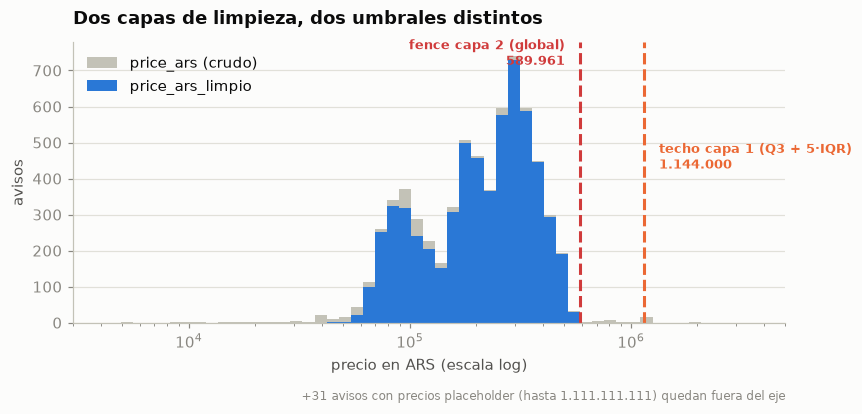

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(3_000), np.log10(5_000_000), 60)
ax.hist(fp["price_ars"].dropna(), bins=bins, color=NEUTRO, label="price_ars (crudo)")
ax.hist(fp["price_ars_limpio"].dropna(), bins=bins, color=S1, label="price_ars_limpio")
ax.set_xscale("log")
ax.set_xlim(3_000, 5_000_000)
tope = ax.get_ylim()[1]

# Las dos lineas caen cerca en escala log: las etiquetas van a distinta altura
# y de lados opuestos para que no se pisen.
ax.axvline(FENCE_C2, color=CRITICO, linewidth=2, linestyle="--")
ax.annotate("fence capa 2 (global)\n{:,.0f}".format(FENCE_C2).replace(",", "."),
            xy=(FENCE_C2, tope * 0.92), xytext=(-10, 0), textcoords="offset points",
            color=CRITICO, fontsize=8.5, fontweight="bold", ha="right")
ax.axvline(TECHO_C1, color=S2, linewidth=2, linestyle="--")
ax.annotate("techo capa 1 (Q3 + 5·IQR)\n{:,.0f}".format(TECHO_C1).replace(",", "."),
            xy=(TECHO_C1, tope * 0.55), xytext=(10, 0), textcoords="offset points",
            color=S2, fontsize=8.5, fontweight="bold")

fuera = int((fp["price_ars"] > 5_000_000).sum())
ax.annotate("+{} avisos con precios placeholder (hasta 1.111.111.111) quedan fuera del eje".format(fuera),
            xy=(1.0, -0.24), xycoords="axes fraction", ha="right", va="top",
            color=MUTED, fontsize=8)
ax.set_title("Dos capas de limpieza, dos umbrales distintos")
ax.set_xlabel("precio en ARS (escala log)")
ax.set_ylabel("avisos")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Qué dice:** el techo de capa 1 está lejos de la masa de datos porque su trabajo es sacar
placeholders (`1.111.111.111`), no afinar. El fence de capa 2 corta mucho más cerca, que es lo
que se espera de un criterio estadístico. Son dos preguntas distintas y por eso son dos flags
distintos.

El techo de capa 1 **se recalcula en cada corrida** como `Q3_global + 5·IQR_global`, en vez de ser
un número fijo en pesos que la inflación volvería obsoleto.

## 3. Los avisos sin atributos: el agujero que encontró la auditoría

514 avisos (7,8%) no tienen Marca/Modelo/Año/Km en **ninguna** captura. No es un problema de orden
de deduplicación: el dato no existe.

La capa 2 agrupaba por `(id_modelo, anio)`, así que estos avisos **no podían ser marcados nunca**
— y entre ellos estaban los 3 precios más extremos de todo el dataset, que entraban limpios a
`price_ars_limpio`, justo la columna documentada como "graficala directo".

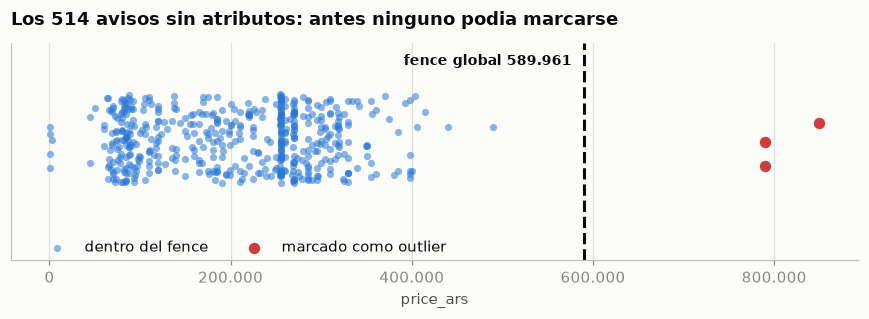

max price_ars_limpio entre los sin atributos:    490,000
max price_ars_limpio entre los que si tienen:    550,000
antes de la correccion, el primero era 850.000


In [6]:
sa = fp[fp["sin_atributos"]]

fig, ax = plt.subplots(figsize=(8, 3))
rng = np.random.default_rng(42)
y = rng.uniform(-0.35, 0.35, len(sa))
marcado = sa["precio_outlier"].to_numpy()

ax.scatter(sa.loc[~marcado, "price_ars"], y[~marcado], s=22, color=S1,
           alpha=0.55, linewidths=0, label="dentro del fence")
ax.scatter(sa.loc[marcado, "price_ars"], y[marcado], s=90, color=CRITICO,
           edgecolors=SURFACE, linewidths=2, zorder=3, label="marcado como outlier")
ax.axvline(FENCE_C2, color=INK, linewidth=2, linestyle="--")
ax.annotate("fence global {:,.0f}".format(FENCE_C2).replace(",", "."),
            xy=(FENCE_C2, 0.58), xytext=(-8, 0), textcoords="offset points",
            color=INK, fontsize=9, fontweight="bold", ha="right")
ax.set_yticks([])
ax.set_ylim(-0.95, 0.75)
ax.set_title("Los 514 avisos sin atributos: antes ninguno podia marcarse")
ax.set_xlabel("price_ars")
ax.xaxis.set_major_formatter(MILES)
ax.legend(frameon=False, loc="lower left", ncol=2, bbox_to_anchor=(0.02, -0.04))
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

con_attrs = fp[~fp["sin_atributos"]]
print("max price_ars_limpio entre los sin atributos: {:>10,.0f}".format(sa["price_ars_limpio"].max()))
print("max price_ars_limpio entre los que si tienen: {:>10,.0f}".format(con_attrs["price_ars_limpio"].max()))
print("antes de la correccion, el primero era 850.000")

**Qué dice:** los 3 puntos rojos son los que se escapaban. Ahora una escalera de dos niveles de
referencia juzga **toda** fila válida en capa 1: por grupo `(id_modelo, anio)` si el grupo tiene
muestra suficiente, y contra la distribución global si no. El contrato es que ninguna fila se
escapa.

Los otros 511 avisos sin atributos conservan su precio: la decisión fue no tirar 511 precios
buenos para sacar 3 malos.

In [7]:
# Como se reparten las filas entre los dos niveles de referencia.
reparto = pd.DataFrame({
    "filas": [120_739, 1_701, 492],
}, index=["tier 1 — grupo (id_modelo, anio)",
          "tier 2 — global: sin modelo/anio",
          "tier 2 — global: grupo sin muestra minima"])
reparto["%"] = (100 * reparto["filas"] / reparto["filas"].sum()).round(1)
reparto

,filas,%
"tier 1 — grupo (id_modelo, anio)",120739,98.2
tier 2 — global: sin modelo/anio,1701,1.4
tier 2 — global: grupo sin muestra minima,492,0.4


## 4. "Estable" no significaba lo que parecía

Con una sola observación válida, `precio_ini == precio_fin` por construcción, la variación da 0 y
el aviso caía en `Estable`. El KPI principal del dashboard reportaba como "precio estable" avisos
de los que no se sabía nada.

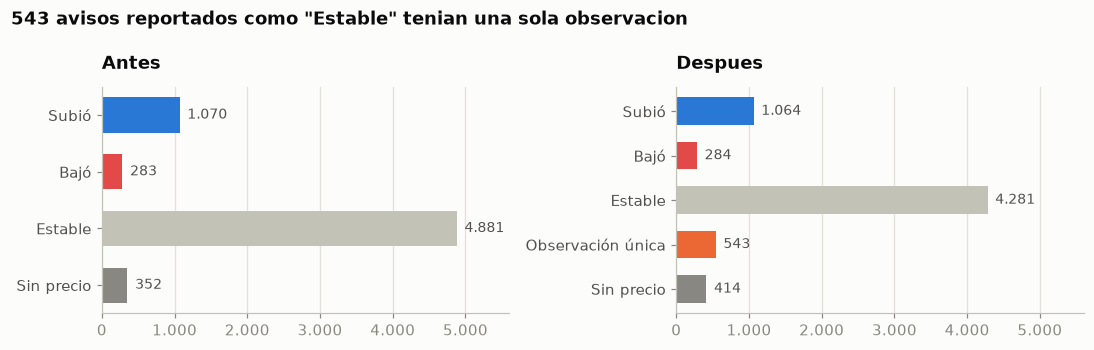

medibles (base del split del dashboard): 5,629 de 6,586 (85.5%)


In [8]:
# Los numeros "antes" salen del commit previo a la auditoria.
ANTES = {"Subió": 1070, "Bajó": 283, "Estable": 4881, "Sin precio": 352}
ahora = tt["tendencia_precio"].value_counts().to_dict()
orden = ["Subió", "Bajó", "Estable", "Observación única", "Sin precio"]
colores = {"Subió": S1, "Bajó": ROJO, "Estable": NEUTRO,
           "Observación única": S2, "Sin precio": MUTED}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, (datos, titulo) in zip(axes, [(ANTES, "Antes"), (ahora, "Despues")]):
    etiquetas = [e for e in orden if e in datos]
    valores = [datos[e] for e in etiquetas]
    ypos = np.arange(len(etiquetas))[::-1]
    ax.barh(ypos, valores, color=[colores[e] for e in etiquetas], height=0.62)
    ax.set_yticks(ypos)
    ax.set_yticklabels(etiquetas, color=INK2)
    for yy, v in zip(ypos, valores):
        ax.annotate("{:,}".format(v).replace(",", "."), xy=(v, yy), xytext=(5, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
    ax.set_title(titulo)
    ax.set_xlim(0, 5600)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelbottom=True)
    ax.xaxis.set_major_formatter(MILES)
fig.suptitle("543 avisos reportados como \"Estable\" tenian una sola observacion",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

print("medibles (base del split del dashboard): {:,} de {:,} ({:.1f}%)".format(
    int(tt["tendencia_medible"].sum()), len(tt), 100 * tt["tendencia_medible"].mean()))

**Qué dice:** `Observación única` no se pliega a `Sin precio` a propósito — esos avisos **sí**
tienen precio válido, solo no tienen con qué compararlo. `Sin precio` responde otra pregunta
(cuántos avisos no tienen ningún precio usable) y mezclarlas corrompería esa métrica.

La columna `tendencia_medible` es sobre la que debe filtrar el dashboard: da un denominador
honesto en vez de repartir porcentajes sobre una base que incluye avisos no medibles.

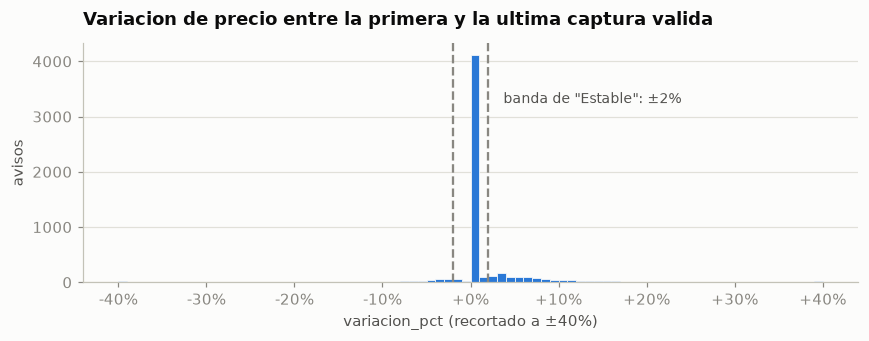

avisos con variacion exactamente 0: 4,096


In [9]:
# Distribucion de la variacion, solo donde se pudo medir de verdad.
medibles = tt[tt["tendencia_medible"]]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(medibles["variacion_pct"].clip(-0.4, 0.4), bins=80, color=S1,
        edgecolor=SURFACE, linewidth=0.5)
for x, col in [(-0.02, MUTED), (0.02, MUTED)]:
    ax.axvline(x, color=col, linewidth=1.5, linestyle="--")
ax.annotate("banda de \"Estable\": ±2%", xy=(0.02, ax.get_ylim()[1] * 0.75),
            xytext=(10, 0), textcoords="offset points", color=INK2, fontsize=9)
ax.set_title("Variacion de precio entre la primera y la ultima captura valida")
ax.set_xlabel("variacion_pct (recortado a ±40%)")
ax.set_ylabel("avisos")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "{:+.0%}".format(v)))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("avisos con variacion exactamente 0: {:,}".format(int((medibles["variacion_pct"] == 0).sum())))

**Qué dice:** la masa está concentrada en 0 — en 73 días la mayoría de los vendedores no tocó el
precio. Eso hace que la distinción con "lo vi una sola vez" importe todavía más: sin separarlas,
el bucket más grande del dashboard mezcla dos cosas que no son lo mismo.

## 5. Kilometraje

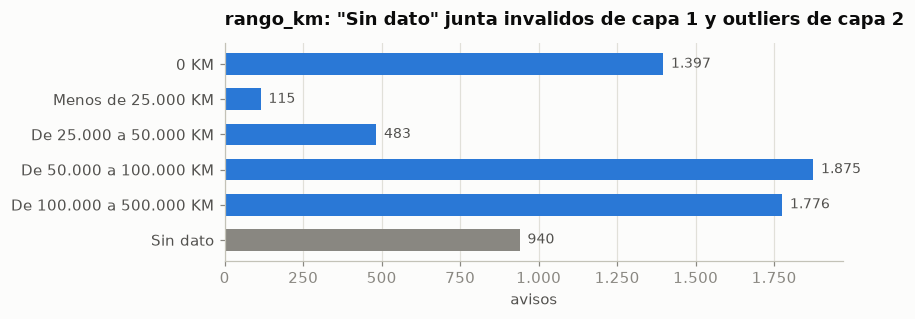

In [10]:
rk = (fp.groupby(["orden_rango_km", "rango_km"]).size()
        .reset_index(name="n").sort_values("orden_rango_km"))

fig, ax = plt.subplots(figsize=(8, 3))
ypos = np.arange(len(rk))[::-1]
ax.barh(ypos, rk["n"], height=0.62,
        color=[MUTED if r == "Sin dato" else S1 for r in rk["rango_km"]])
ax.set_yticks(ypos)
ax.set_yticklabels(rk["rango_km"], color=INK2)
for yy, v in zip(ypos, rk["n"]):
    ax.annotate("{:,}".format(v).replace(",", "."), xy=(v, yy), xytext=(5, 0),
                textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set_title("rango_km: \"Sin dato\" junta invalidos de capa 1 y outliers de capa 2")
ax.set_xlabel("avisos")
ax.xaxis.set_major_formatter(MILES)
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Qué dice:** `rango_km` se calcula sobre `kilometros_limpio`, no sobre el crudo, así que un
outlier de capa 2 cae en "Sin dato" igual que un inválido de capa 1 — antes los outliers quedaban
clasificados en un rango real.

Falta una categoría: **"Más de 500.000 KM" es inalcanzable con este dataset**. No hay ningún aviso
con km entre 500.000 y los 800.000 del corte de validez (el máximo válido es 490.000), así que esa
categoría es una entrada de leyenda que nunca aparece.

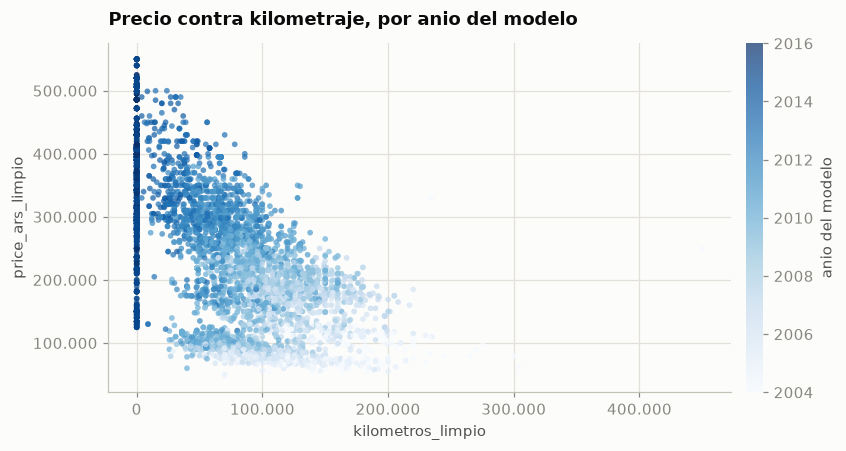

In [11]:
sub = fp.dropna(subset=["price_ars_limpio", "kilometros_limpio", "anio_limpio"])

fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(sub["kilometros_limpio"], sub["price_ars_limpio"],
                c=sub["anio_limpio"], cmap="Blues", s=14, alpha=0.7, linewidths=0,
                vmin=sub["anio_limpio"].quantile(0.02))
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("anio del modelo", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Precio contra kilometraje, por anio del modelo")
ax.set_xlabel("kilometros_limpio")
ax.set_ylabel("price_ars_limpio")
ax.xaxis.set_major_formatter(MILES)
ax.yaxis.set_major_formatter(MILES)
ax.grid()
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Qué dice:** la relación esperada (más km, menos precio) aparece, y el año explica buena parte de
la dispersión vertical — que es exactamente la razón por la que la capa 2 agrupa por
`(id_modelo, anio)` y no por modelo solo. Un fence de precio calculado sobre todos los años juntos
marcaría autos nuevos baratos y viejos caros sin que ninguno sea un error.

También es la razón por la que **km no tiene tier global**: a diferencia del precio, un fence de
kilometraje sobre toda la población mezclaría años y no significaría nada.

## 6. Tipo de cambio

In [12]:
print(dim_fx.to_string(index=False))
print()
usd = fp["currency_id"].eq("USD")
print("avisos publicados en USD: {} de {:,} ({:.2f}%)".format(
    int(usd.sum()), len(fp), 100 * usd.mean()))
print()
print("La columna fuente_fx deja el linaje visible EN EL MODELO: quien abra el")
print("dashboard puede ver si la cotizacion salio de la API, de un override o")
print("del fallback. Antes, una API caida devolvia los mismos valores que la API")
print("real para nov-2015, asi que la falla era invisible.")

  fecha_fx  usd_oficial  usd_blue fuente_fx
2015-11-30         10.0      15.0  override

avisos publicados en USD: 12 de 6,586 (0.18%)

La columna fuente_fx deja el linaje visible EN EL MODELO: quien abra el
dashboard puede ver si la cotizacion salio de la API, de un override o
del fallback. Antes, una API caida devolvia los mismos valores que la API
real para nov-2015, asi que la falla era invisible.


**Qué dice:** `dim_FX` es un par de escalares para todo el período, no una serie diaria. Alcanza
para una ventana de 73 días; para un rango más largo habría que modelarla como serie y relacionarla
con `dim_fecha`.

Solo el 0,09% de los avisos se publica en USD, pero el dólar blue se usa igual para normalizarlos
a pesos, así que la cotización entra en `price_ars` de esas filas.

---

## Qué quedó afuera

- **El `.pbix` y las medidas DAX.** Este repo es la capa de datos.
- **`dim_FX` es un par de escalares, no una serie diaria.** Alcanza para una ventana de 73 días;
  para un rango más largo habría que modelarla como serie y relacionarla con `dim_fecha`.
- **Solo 3 marcas y 3 modelos.** Es el dataset, no un filtro.